In [1]:
import polars as pl
import seaborn as sns
sns.set_theme()
import random



In [2]:
papers = pl.read_parquet("/dataHDD1/pmData/s2orcParsed/combinedPapers.parquet")

In [3]:
import json
import numpy as np
from scipy.stats import skew, kurtosis
import csv
import pandas as pd

df_exploded = papers.explode('s2fieldsofstudy')
exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
df_sep = pl.from_dicts(exploded_list)
df_res = df_exploded.with_columns(df_sep)
df_filter = df_res.filter((pl.col("source") == "external") & (pl.col("isopenaccess") == True))
df_filter = df_filter.with_columns(
    pl.col("year").cast(pl.Int32).alias("year")
)

print("len: ", len(df_filter))

len:  6968058


In [4]:
ccList = papers["citationcount"].to_list()
ccList.sort()
ccList

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


In [5]:

import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


[0.         0.         0.         ... 0.97904427 2.18455106 1.87575781]
shape: (10_819_875, 17)
┌──────────┬───────────┬──────────┬──────────┬───┬────────────┬────────────┬──────────┬────────────┐
│ corpusid ┆ externali ┆ url      ┆ title    ┆ … ┆ publicatio ┆ publicatio ┆ journal  ┆ boxcoxCita │
│ ---      ┆ ds        ┆ ---      ┆ ---      ┆   ┆ ntypes     ┆ ndate      ┆ ---      ┆ tionCount  │
│ i64      ┆ ---       ┆ str      ┆ str      ┆   ┆ ---        ┆ ---        ┆ struct[3 ┆ ---        │
│          ┆ struct[8] ┆          ┆          ┆   ┆ list[str]  ┆ str        ┆ ]        ┆ f64        │
╞══════════╪═══════════╪══════════╪══════════╪═══╪════════════╪════════════╪══════════╪════════════╡
│ 25930995 ┆ {null,nul ┆ https:// ┆ Single   ┆ … ┆ ["JournalA ┆ 2023-07-03 ┆ {"Fronti ┆ 0.0        │
│ 0        ┆ l,"259309 ┆ www.sema ┆ cell     ┆   ┆ rticle"]   ┆            ┆ ers in   ┆            │
│          ┆ 950",null ┆ nticscho ┆ analysis ┆   ┆            ┆            ┆ Aging",n ┆         

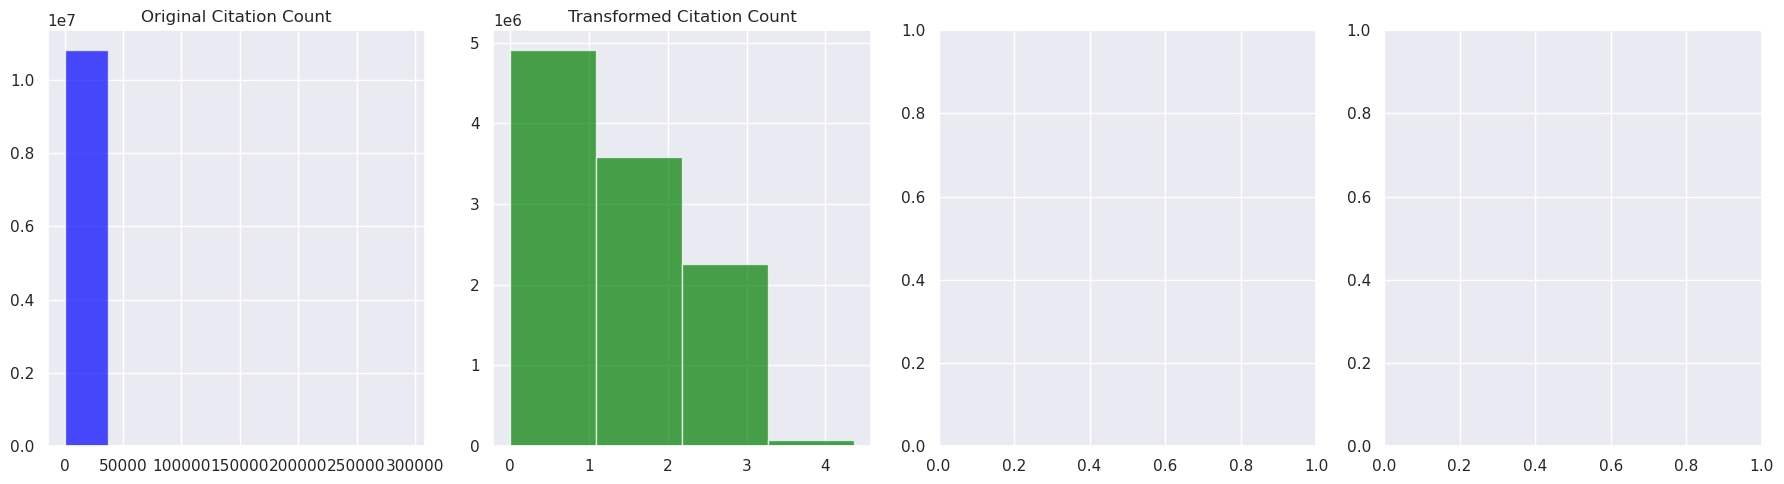

In [5]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

ccList = papers["citationcount"].to_list()
# ccList.sort()
ccList


# Sample data for Citation Count and Total Records columns
citation_count = np.array(ccList)
constant = 1

# Perform Box-Cox transformation for both columns
transformed_citation_count, lambda_citation = stats.boxcox(citation_count + 1)

papers = papers.with_columns(boxcoxCitationCount = pl.lit(transformed_citation_count))

print(transformed_citation_count)
print(papers)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Plot original Citation Count histogram
axes[0].hist(citation_count, bins=8, color='blue', alpha=0.7)
axes[0].set_title('Original Citation Count')

# Plot transformed Citation Count histogram
axes[1].hist(transformed_citation_count, bins=4, color='green', alpha=0.7)
axes[1].set_title('Transformed Citation Count')


# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [6]:
import json
import numpy as np
from scipy.stats import skew, kurtosis
import csv
import pandas as pd

df_exploded = papers.explode('s2fieldsofstudy')
exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
df_sep = pl.from_dicts(exploded_list)
df_res = df_exploded.with_columns(df_sep)
df_filter = df_res.filter(pl.col("source") == "external")
grouped = df_filter.groupby('category')
newDF = []
fos = []
grp = []

records = []
results = []

csv_list = []

for cat, group in grouped:
    
    ccList = group["citationcount"].to_list()
    carr = np.array(ccList)

    
    
    # Sample data for Citation Count and Total Records columns
    citation_count = np.array(ccList)
    constant = 1

    # Perform Box-Cox transformation for both columns
    transformed_citation_count, lambda_citation = stats.boxcox(citation_count + 1)
    
    sk = skew(group["citationcount"])
    kr = kurtosis(group["citationcount"])
    
    filtered_ccList = [x + 1 for x in ccList]
    log_list = list(np.log(filtered_ccList))
    log_sk=skew(log_list)
    log_kr=kurtosis(log_list)
    
    bc_sk = skew(transformed_citation_count)
    bc_kr = kurtosis(transformed_citation_count)

    
    obj = {"field":cat, "skew": sk, "kurtosis" : kr, "skew_log": log_sk, "kurtosis_log": log_kr, "skew_bc": bc_sk, "kurtosis_bc":bc_kr}
    csv_list.append(obj)

    group = group.with_columns(boxcoxCitationCount = pl.lit(transformed_citation_count))
    
    group_pd = group.to_pandas()

    # res = getCitationCountBF(cat,group)
    # records.append(res[0])
    # results.append(res[1])
    # fig, axes = plt.subplots(figsize=(5, 5))
    
    
    
    # Calculate the initial histogram
    hist, bin_edges = np.histogram(group_pd["boxcoxCitationCount"], bins=7)

    # Check for empty bins
    empty_bins = np.where(hist == 0)[0]

    if empty_bins.size > 0:
        # Calculate the new bin edges by distributing the empty bins
        new_bin_edges = np.linspace(min(group_pd["boxcoxCitationCount"]), max(group_pd["boxcoxCitationCount"]), 7 + 1)
        new_hist, _ = np.histogram(group_pd["boxcoxCitationCount"], bins=new_bin_edges)
        
        print("Original bin edges:", bin_edges)
        print("Original histogram:", hist)
        print("New bin edges:", new_bin_edges)
        print("New histogram:", new_hist)
    
    
    
    
    
    

#     (n, bins, patches) = axes.hist(transformed_citation_count, bins=3, color='green', alpha=0.7)
#     # print(cat)
#     # print(list(bins))
#     group_pd['bins'] = None 
    
#     for i,bin in enumerate(bins):
#         if i+1 < len(bins):
            
#             print(bins[i],bins[i+1] )
            
#             mask = (group_pd['boxcoxCitationCount'] < bins[i + 1]) & (group_pd['boxcoxCitationCount'] >= bins[i])
#             group_pd.loc[mask, 'bins'] = i + 1
            
#     # print(group_pd.head())
#     unique_values = group_pd["bins"].unique()
#     filtered_records = group_pd[group_pd['bins'] == 1]

#     print(unique_values)
    
           
        
    


    

#     axes.set_title('Transformed Citation Count')
    
#     fig, axes = plt.subplots(figsize=(5, 5))

#     (n, bins, patches) = axes.hist(citation_count, bins=5, color='green', alpha=0.7)
#     # print(cat)
#     # print(bins)

#     axes.set_title('Transformed Citation Count Test')
    

# jsonRecords = json.dumps(records, indent=4)
    
# with open("binInfoDepth1.json", "w") as outfile:
#     outfile.write(jsonRecords)
    
# # Specify the CSV file name
# csv_filename = "fieldStats.csv"

# # Write the data to a CSV file
# with open(csv_filename, mode="w", newline="", encoding="utf-8") as file:
#     fieldnames = ["field", "skew", "kurtosis", "skew_log", "kurtosis_log", "skew_bc", "kurtosis_bc"]
#     writer = csv.DictWriter(file, fieldnames=fieldnames)
    
#     writer.writeheader()
#     for entry in csv_list:
#         writer.writerow(entry)

Original bin edges: [0.         0.16165632 0.32331263 0.48496895 0.64662526 0.80828158
 0.96993789 1.13159421]
Original histogram: [13666     0     0  4072  3124  2145  2347]
New bin edges: [0.         0.16165632 0.32331263 0.48496895 0.64662526 0.80828158
 0.96993789 1.13159421]
New histogram: [13666     0     0  4072  3124  2145  2347]
Original bin edges: [0.         0.15136694 0.30273388 0.45410082 0.60546776 0.7568347
 0.90820165 1.05956859]
Original histogram: [6771    0    0 1887  911 1331 1262]
New bin edges: [0.         0.15136694 0.30273388 0.45410082 0.60546776 0.7568347
 0.90820165 1.05956859]
New histogram: [6771    0    0 1887  911 1331 1262]


In [4]:
import json
import numpy as np
from scipy.stats import skew, kurtosis
import csv
import pandas as pd

df_exploded = papers.explode('s2fieldsofstudy')
exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
df_sep = pl.from_dicts(exploded_list)
df_res = df_exploded.with_columns(df_sep)
df_filter = df_res.filter((pl.col("source") == "external") & (pl.col("isopenaccess") == True))
df_filter = df_filter.with_columns(
    pl.col("year").cast(pl.Int32).alias("year")
)

print("len: ", len(df_filter))
grouped = df_filter.groupby('category')
newDF = []
fos = []
grp = []

records = []
results = []

csv_list = []

df = pd.DataFrame()
catList = []
yearList= []
ccListDF = []

df_filter = df_filter.select(["corpusid", "year", "citationcount","category"])
df_filter = df_filter.with_columns(pl.lit(None).alias("group"))

filter_list = []

yearsCount = 0
cCount = 0
c = 0
for cat, group in grouped:
    print(cat)
    c += len(group)
    
    per = (len(group)/6968058) * 100
    if per >= 3:
        for i in [(1996,2000),(2001,2005),(2006,2010),(2011,2015),(2016,2020)]:

            group_filter = group.filter(pl.col("year").is_in(list(range(i[0],i[1] + 1))))
            print("----------------------")
            yearsCount += len(group_filter)
            
                
            ccList = group_filter["citationcount"].to_list()
            cc = sorted(set(ccList))
                
            if len(cc) > 10:
                
                elements_per_group = int(len(cc) / 10)

                    
                groups = [cc[i:i+elements_per_group] for i in range(0, len(cc), elements_per_group)]
                for ind,j in enumerate(groups[:10]):
                    catList.append(cat)
                    yearList.append(str(i))
                    ccListDF.append(str(j))
                        
                        
                        # total_matching_records = (
                        #     (df_filter_pd["category"] == cat) &
                        #     (df_filter_pd["year"].isin(list(range(i[0], i[1])))) &
                        #     (df_filter_pd["citationcount"].isin(j))
                        # ).sum()
                        
                        # print(str(ind))

                        
                        # df_filter_pd.loc[
                        #     (df_filter_pd["category"] == cat) &
                        #     df_filter_pd["year"].isin(list(range(i[0], i[1]))) &
                        #     df_filter_pd["citationcount"].isin(j),
                        #     "group"
                        # ] = ind
                        
                    df_filter_1 = df_filter.filter(
                        (df_filter["category"] == cat) &
                        df_filter["year"].is_in(list(range(i[0], i[1] + 1))) &
                        df_filter["citationcount"].is_in(j)
                    ).with_columns(
                            pl.lit(ind).alias("group")
                        )
                    cCount += len(df_filter_1)
                    filter_list.append(df_filter_1)
                
df["field"] = catList
df["year"] = yearList
df["cc"] = ccListDF
concatenated_df = pl.concat(filter_list)
concatenated_df.write_parquet("/dataHDD1/pmData/s2orcParsed/filteredGroup.parquet")
print("total: ", c)
print(len(concatenated_df))
print(yearsCount)
print(cCount)


len:  6968058
Chemistry
----------------------
----------------------
----------------------
----------------------
----------------------
Philosophy
Psychology
Computer Science
----------------------
----------------------
----------------------
----------------------
----------------------
Engineering
Materials Science
----------------------
----------------------
----------------------
----------------------
----------------------
Geology
History
Sociology
Environmental Science
Geography
Physics
----------------------
----------------------
----------------------
----------------------
----------------------
Medicine
----------------------
----------------------
----------------------
----------------------
----------------------
Business
Political Science
Mathematics
----------------------
----------------------
----------------------
----------------------
----------------------
Biology
----------------------
----------------------
----------------------
----------------------
---

In [3]:
df = pl.read_parquet("/dataHDD1/pmData/s2orcParsed/filteredGroup.parquet")
grouped = df.groupby('category')

final = []
lenData = []
locData = []
typeData = []

c = 0
for cat, grp in grouped:
    print(cat)

    for i in [(1996,2000),(2001,2005),(2006,2010),(2011,2015),(2016,2020)]:
        for j in range(10):
            temp_cid = []
            grp_test = grp.filter(
                (pl.col("year").is_in(list(range(i[0], i[1] + 1)))) &
                (pl.col("group") == j) & 
                (pl.col("citationcount") >= 5)
            ) 
            grp_test_list = grp_test["corpusid"].to_list()
            
            print(str(i[0]) + "-" + str(i[1] + 1) + ":"  + str(j) + ":" + str(len(grp_test_list)))
            
            random.shuffle(grp_test_list)
            
                                 
            filtered_df = grp_test.filter(pl.col("corpusid").is_in(grp_test_list[:20]))[:20]
            lenData.append(filtered_df)
            
            filtered_df = grp_test.filter(pl.col("corpusid").is_in(grp_test_list[20:40]))[:20]
            locData.append(filtered_df)
            
            filtered_df = grp_test.filter(pl.col("corpusid").is_in(grp_test_list[40:60]))[:20]
            typeData.append(filtered_df)

    print("=================================================")

lenConcat = pl.concat(lenData)
locConcat = pl.concat(locData)
typeConcat = pl.concat(typeData)

Chemistry
1996-2001:0:3854
1996-2001:1:2039
1996-2001:2:907
1996-2001:3:425
1996-2001:4:247
1996-2001:5:146
1996-2001:6:111
1996-2001:7:82
1996-2001:8:69
1996-2001:9:64
2001-2006:0:5977
2001-2006:1:2485
2001-2006:2:964
2001-2006:3:442
2001-2006:4:240
2001-2006:5:146
2001-2006:6:109
2001-2006:7:77
2001-2006:8:60
2001-2006:9:58
2006-2011:0:13419
2006-2011:1:3207
2006-2011:2:945
2006-2011:3:406
2006-2011:4:230
2006-2011:5:125
2006-2011:6:100
2006-2011:7:89
2006-2011:8:70
2006-2011:9:63
2011-2016:0:43930
2011-2016:1:5677
2011-2016:2:1375
2011-2016:3:553
2011-2016:4:249
2011-2016:5:173
2011-2016:6:104
2011-2016:7:94
2011-2016:8:77
2011-2016:9:70
2016-2021:0:177739
2016-2021:1:9725
2016-2021:2:1983
2016-2021:3:701
2016-2021:4:334
2016-2021:5:175
2016-2021:6:109
2016-2021:7:96
2016-2021:8:77
2016-2021:9:63
Materials Science
1996-2001:0:1356
1996-2001:1:477
1996-2001:2:215
1996-2001:3:100
1996-2001:4:70
1996-2001:5:54
1996-2001:6:50
1996-2001:7:42
1996-2001:8:35
1996-2001:9:33
2001-2006:0:4428

KeyboardInterrupt: 

In [7]:
lenConcat.write_parquet("/dataHDD1/pmData/s2orcParsed/len.parquet")
locConcat.write_parquet("/dataHDD1/pmData/s2orcParsed/loc.parquet")
typeConcat.write_parquet("/dataHDD1/pmData/s2orcParsed/type.parquet")


In [8]:
len(lenConcat)

3500

In [ ]:


        
        
        # # Sample data for Citation Count and Total Records columns
        # citation_count = np.array(ccList)
        # constant = 1

        # # Perform Box-Cox transformation for both columns
        # transformed_citation_count, lambda_citation = stats.boxcox(citation_count + 1)
        
        # sk = skew(group_filter["citationcount"])
        # kr = kurtosis(group_filter["citationcount"])
        
        # filtered_ccList = [x + 1 for x in ccList]
        # log_list = list(np.log(filtered_ccList))
        # log_sk=skew(log_list)
        # log_kr=kurtosis(log_list)
        
        # bc_sk = skew(transformed_citation_count)
        # bc_kr = kurtosis(transformed_citation_count)

        
        # obj = {"field":cat, "skew": sk, "kurtosis" : kr, "skew_log": log_sk, "kurtosis_log": log_kr, "skew_bc": bc_sk, "kurtosis_bc":bc_kr}
        # csv_list.append(obj)

        # group_filter = group_filter.with_columns(boxcoxCitationCount = pl.lit(transformed_citation_count))
        
        # group_pd = group_filter.to_pandas()

        # # res = getCitationCountBF(cat,group)
        # # records.append(res[0])
        # # results.append(res[1])
        # fig, axes = plt.subplots(figsize=(5, 5))
        
        # (n, bins, patches) = axes.hist(transformed_citation_count, bins=10, color='green', alpha=0.7)
        # # print(cat)
        # # print(list(bins))
        # group_pd['bins'] = None 
        
        # for i,bin in enumerate(bins):
        #     if i+1 < len(bins):
                
        #         print(bins[i],bins[i+1])
                
        #         mask = (group_pd['boxcoxCitationCount'] < bins[i + 1]) & (group_pd['boxcoxCitationCount'] >= bins[i])
        #         group_pd.loc[mask, 'bins'] = i + 1
                
        # # print(group_pd.head())
        # unique_values = group_pd["bins"].unique()
        # filtered_records = group_pd[group_pd['bins'] == 1]

        # print(unique_values)
        
        
        # 10


In [80]:
def getCitationCountDF(cat,group):
    size = int(len(group["boxcoxCitationCount"]) / 7)
    bins = []
    dfList = []
        
    for ind,i in enumerate(range(0, len(group["boxcoxCitationCount"]), size )):
        tempDf = pl.DataFrame()
        group = group.sort(["boxcoxCitationCount"]) 
        selectedGroup = group[i: i + size]
        tempDf = tempDf.with_columns(id = pl.lit(selectedGroup["corpusid"]))
        tempDf = tempDf.with_columns(field = pl.lit(cat))
        tempDf = tempDf.with_columns(bin = ind)
        bin = {"max":max(selectedGroup["boxcoxCitationCount"]), "min":min(selectedGroup["boxcoxCitationCount"]),"bin": ind, "total_records": len(selectedGroup)}     
        bins.append(bin)
        dfList.append(tempDf)

    dfJoined = pl.concat(dfList)

    return ({cat: bins},dfJoined)

In [83]:
def getCitationCountBF(cat,group):
    rn = int((max(group["boxcoxCitationCount"]) - min(group["boxcoxCitationCount"]))/ 5)
    bins = []
    bfList = []

    for ind,i in enumerate(range(min(group["boxcoxCitationCount"]), max(group["boxcoxCitationCount"]), rn )):
        tempDf = pl.DataFrame()
        group = group.sort(["citationcount"])        
        filtered = group.filter((pl.col("boxcoxCitationCount") >= i) & (pl.col("boxcoxCitationCount") < i + rn))

        total =  len(filtered["boxcoxCitationCount"]) if not filtered.is_empty() else 0

        tempDf = tempDf.with_columns(id = pl.lit(filtered["corpusid"]))
        tempDf = tempDf.with_columns(field = pl.lit(cat))
        tempDf = tempDf.with_columns(bin = ind)
        
        bin = {"min":i,"max":i + rn - 1, "bin": ind, "total_records": total}
        
        bins.append(bin)
        bfList.append(tempDf)

    bfJoined = pl.concat(bfList)

    return ({cat: bins},bfJoined)

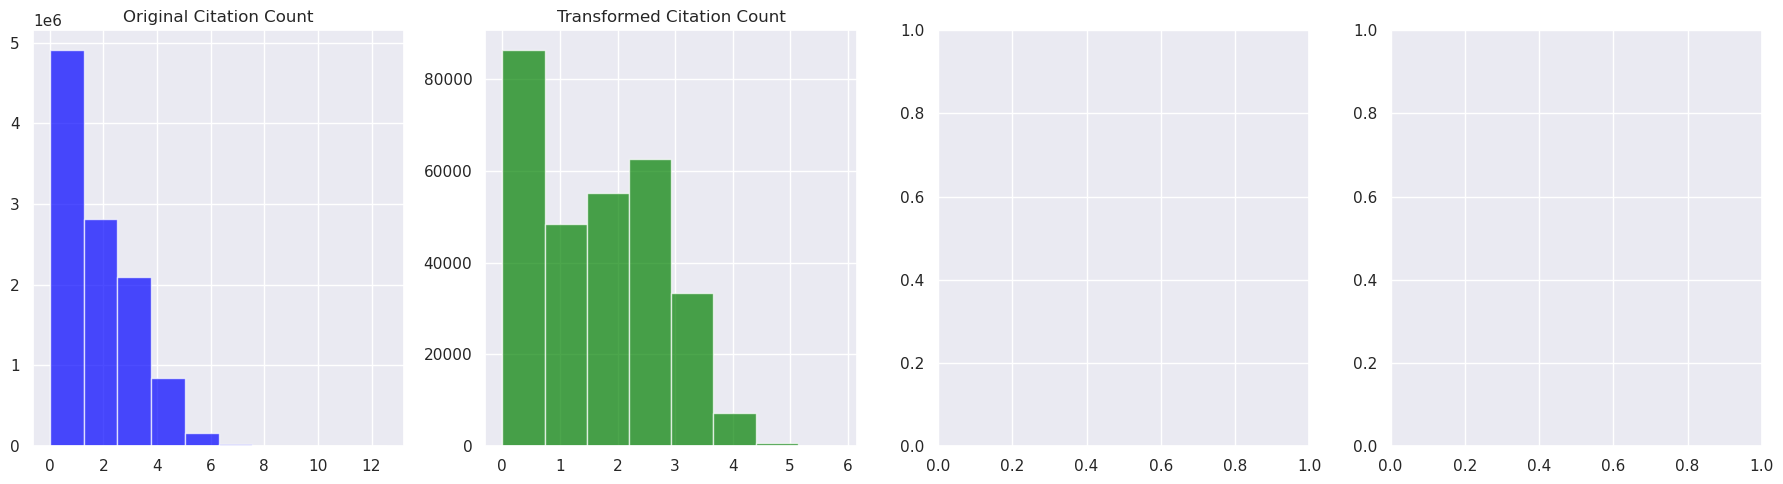

In [50]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

ccList = papers["citationcount"].to_list()
ccList.sort()
ccList


# Sample data for Citation Count and Total Records columns
citation_count = np.array(ccList)
constant = 1

# Perform Box-Cox transformation for both columns
lambda_citation = np.log(citation_count + 1)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Plot original Citation Count histogram
axes[0].hist(lambda_citation, bins=10, color='blue', alpha=0.7)
axes[0].set_title('Original Citation Count')

# # Plot transformed Citation Count histogram
axes[1].hist(transformed_citation_count, bins=8, color='green', alpha=0.7)
axes[1].set_title('Transformed Citation Count')


# Adjust layout and display the plot
plt.tight_layout()
plt.show()

Physics
----------------------
71647
0.0 0.10905744039311599
0.10905744039311599 0.21811488078623198
0.21811488078623198 0.32717232117934797
[1 3 None]
----------------------
115494
0.0 0.10905744039311599
0.10905744039311599 0.21811488078623198
0.21811488078623198 0.32717232117934797
[1 3 None]
----------------------
163613
0.0 0.10905744039311599
0.10905744039311599 0.21811488078623198
0.21811488078623198 0.32717232117934797
[1 3 None]
----------------------
222254
0.0 0.10905744039311599
0.10905744039311599 0.21811488078623198
0.21811488078623198 0.32717232117934797
[1 3 None]
----------------------
379459
0.0 0.10905744039311599
0.10905744039311599 0.21811488078623198
0.21811488078623198 0.32717232117934797
[1 3 None]
Environmental Science
----------------------
349
0.0 0.10725036965238736
0.10725036965238736 0.21450073930477473
0.21450073930477473 0.3217511089571621
[3 1 None]
----------------------
837
0.0 0.10725036965238736
0.10725036965238736 0.21450073930477473
0.214500739304

/tmp/ipykernel_762766/1058824655.py:68: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(figsize=(5, 5))


0.0 0.3796576342278237
0.3796576342278237 0.7593152684556475
0.7593152684556475 1.1389729026834712
[1 2 3 None]
----------------------
35964
0.0 0.3796576342278237
0.3796576342278237 0.7593152684556475
0.7593152684556475 1.1389729026834712
[1 2 3 None]
----------------------
81461
0.0 0.3796576342278237
0.3796576342278237 0.7593152684556475
0.7593152684556475 1.1389729026834712
[1 2 3 None]
----------------------
253306
0.0 0.3796576342278237
0.3796576342278237 0.7593152684556475
0.7593152684556475 1.1389729026834712
[1 2 3 None]
----------------------
387369
0.0 0.3796576342278237
0.3796576342278237 0.7593152684556475
0.7593152684556475 1.1389729026834712
[1 2 3 None]
Political Science
----------------------
176
0.0 0.06021829668841867
0.06021829668841867 0.12043659337683733
0.12043659337683733 0.180654890065256
[1 3 None]
----------------------
404
0.0 0.06021829668841867
0.06021829668841867 0.12043659337683733
0.12043659337683733 0.180654890065256
[1 3 None]
----------------------
1

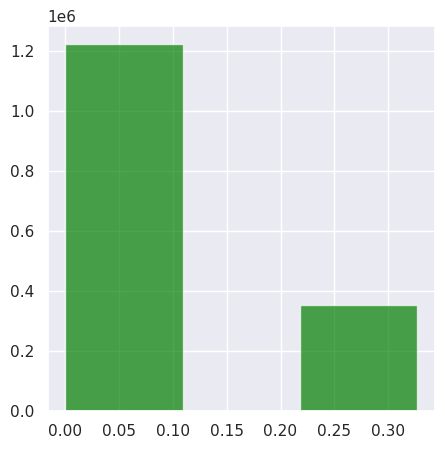

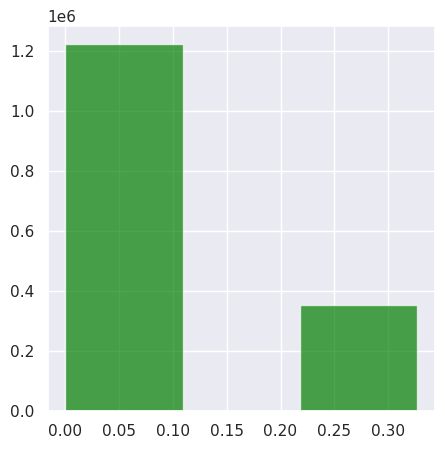

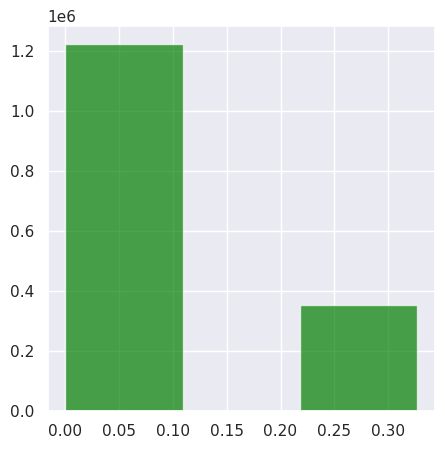

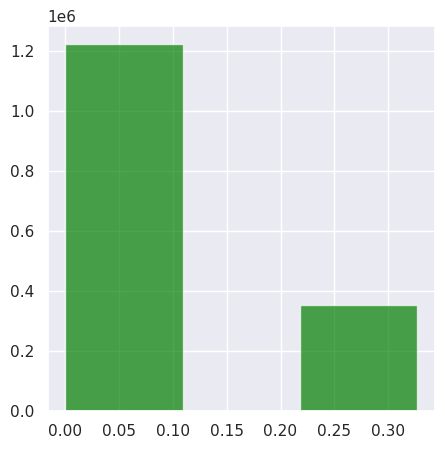

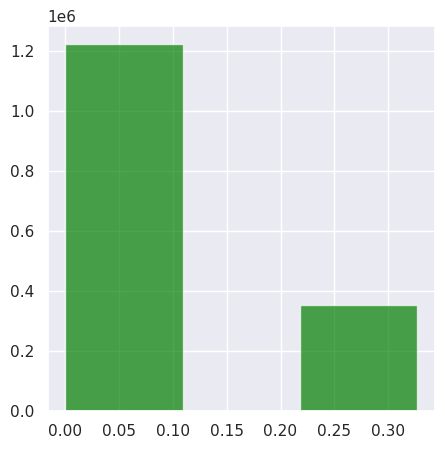

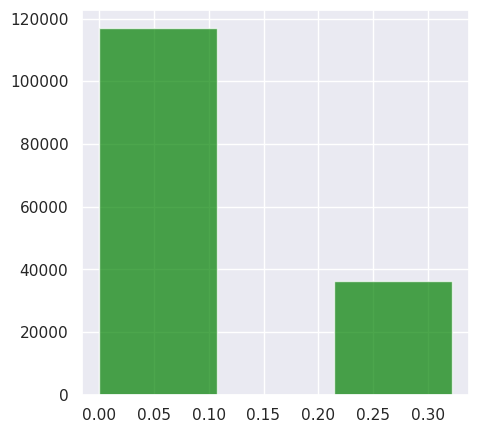

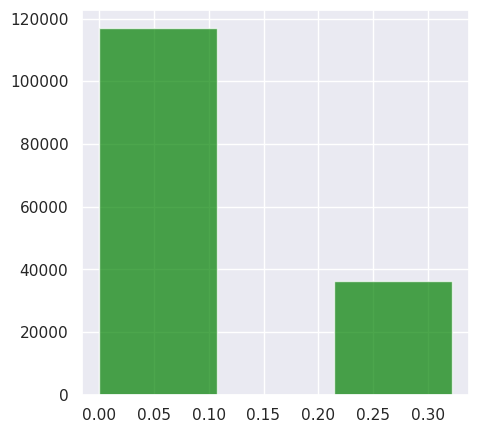

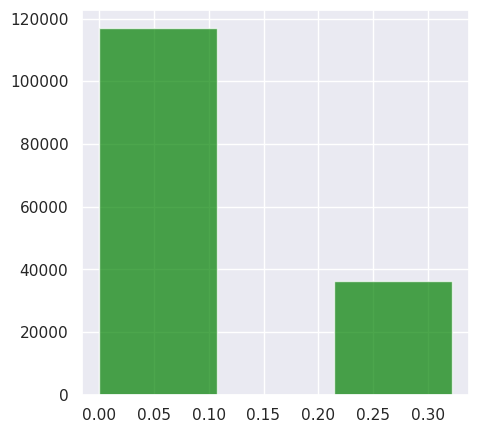

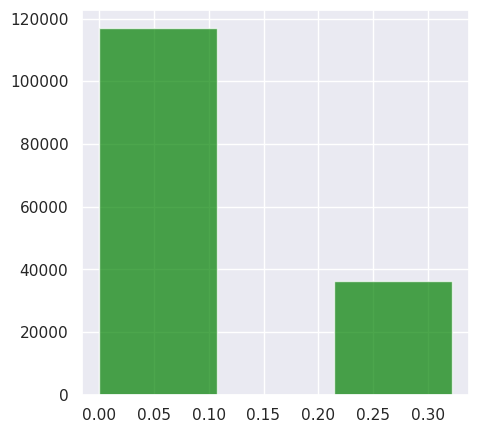

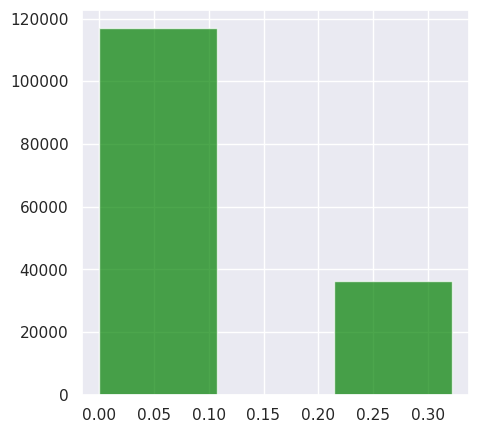

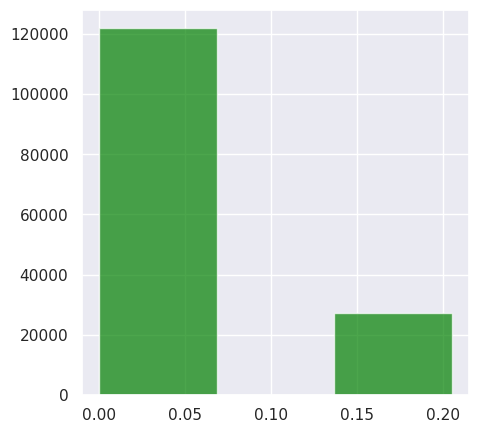

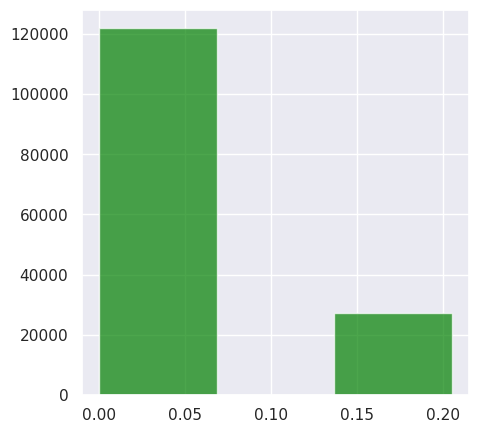

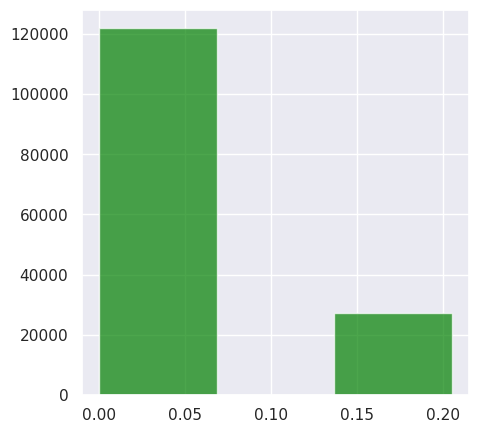

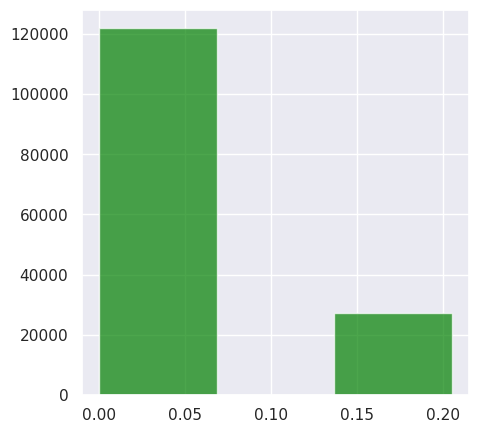

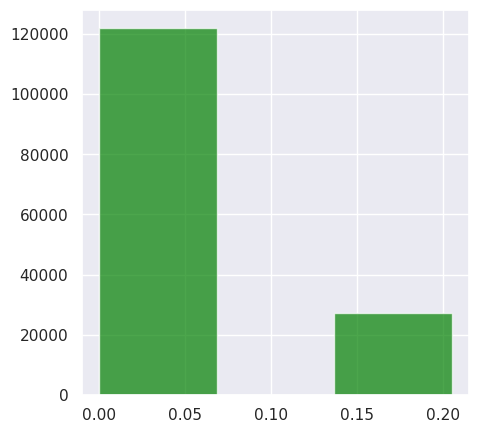

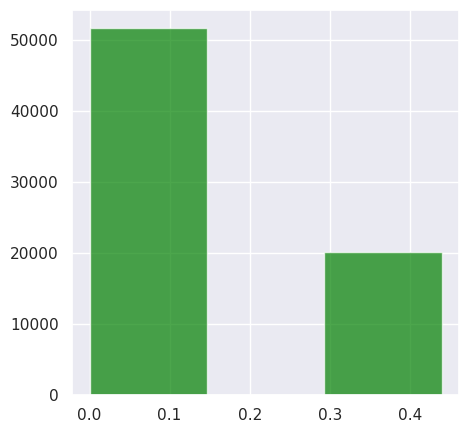

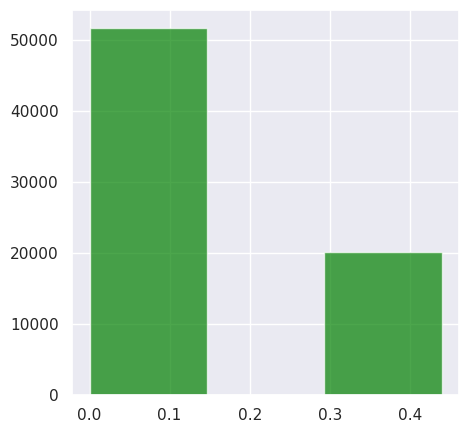

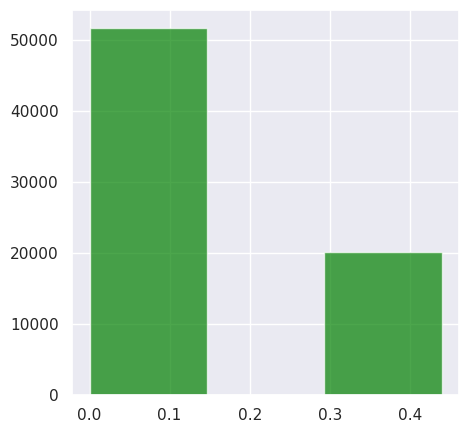

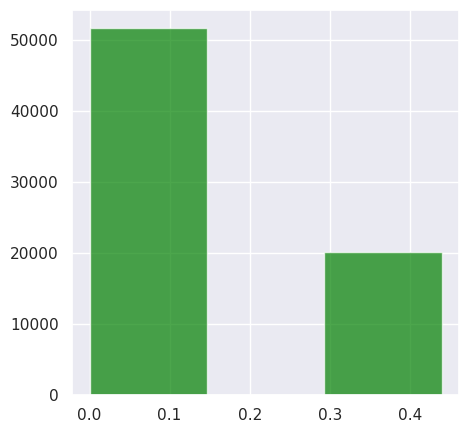

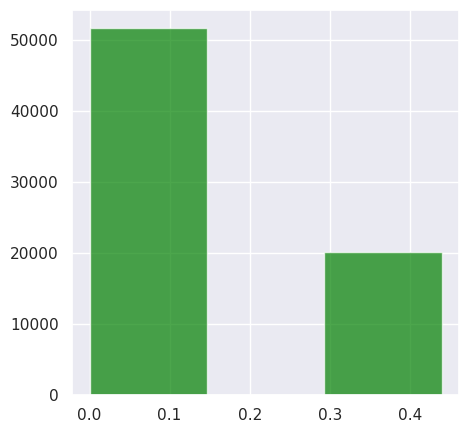

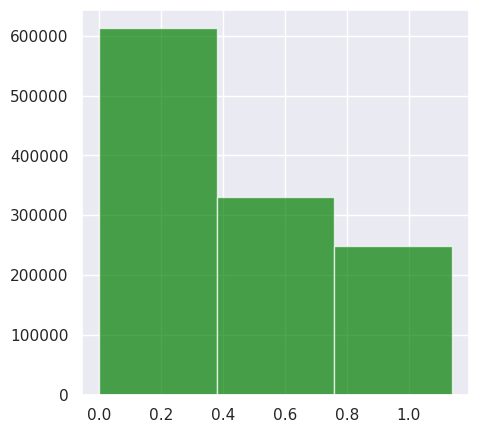

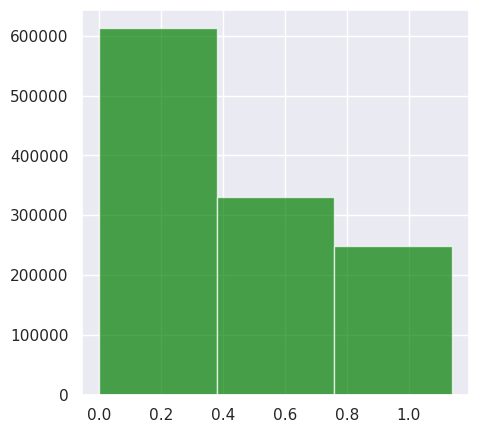

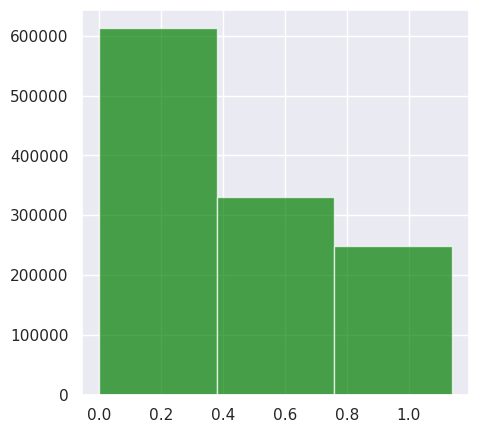

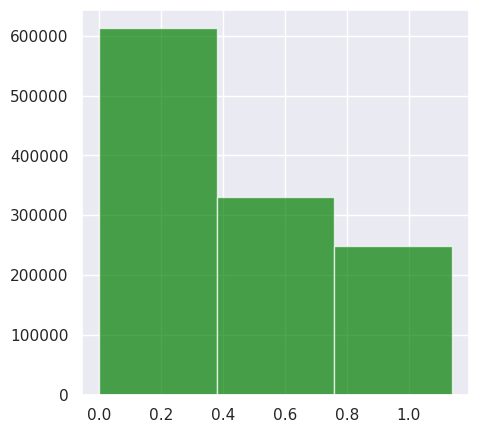

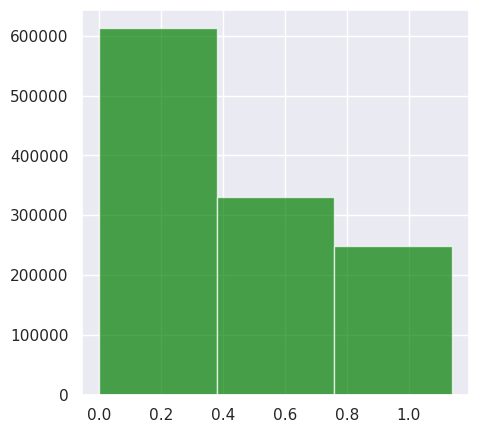

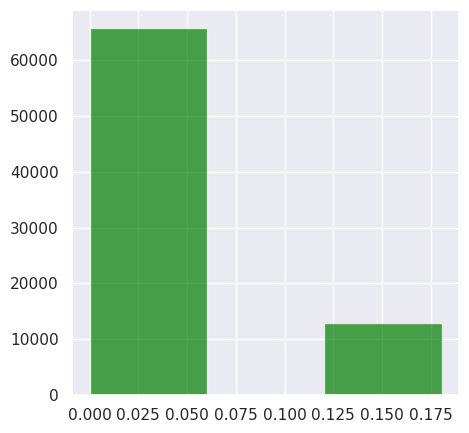

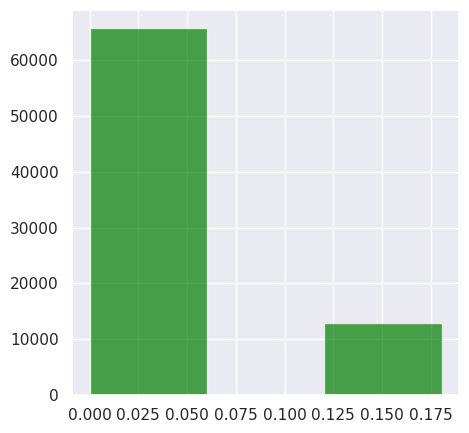

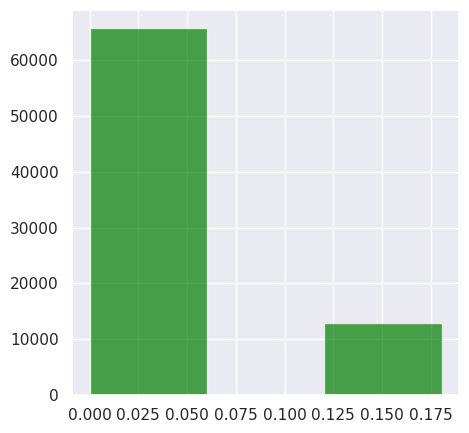

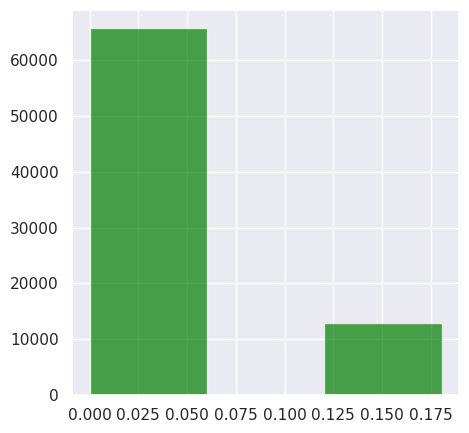

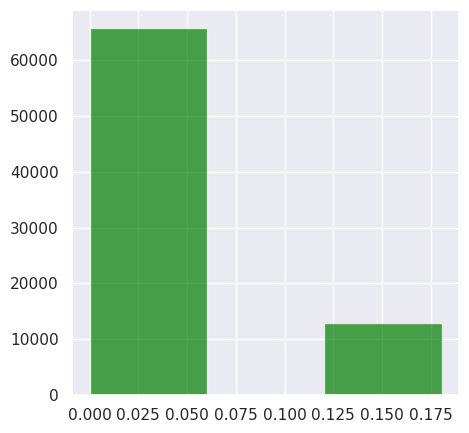

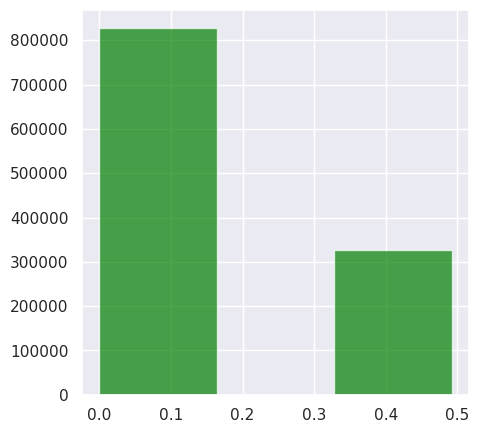

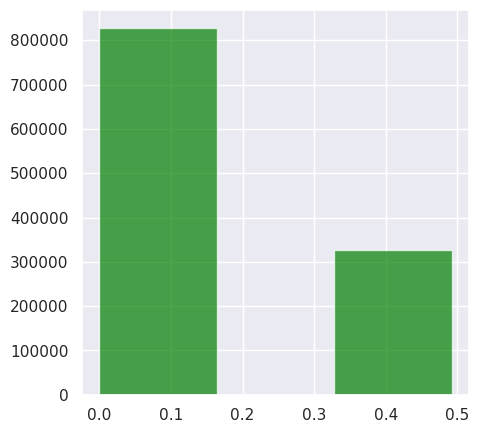

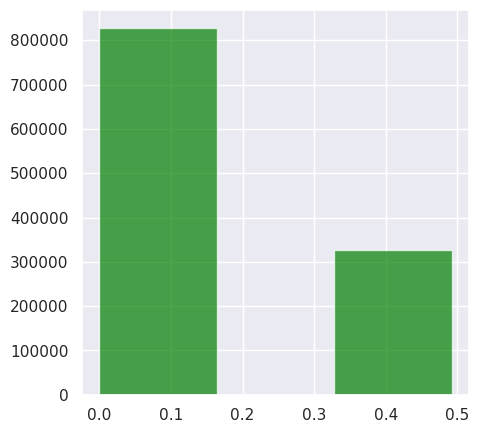

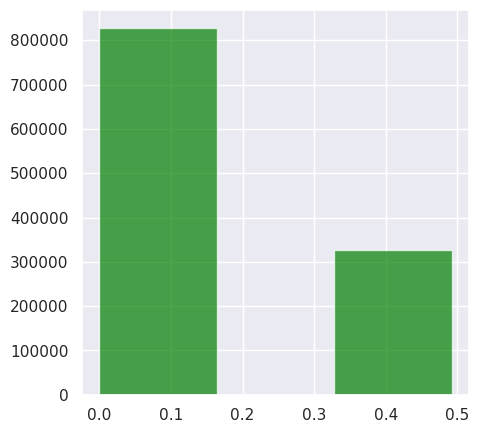

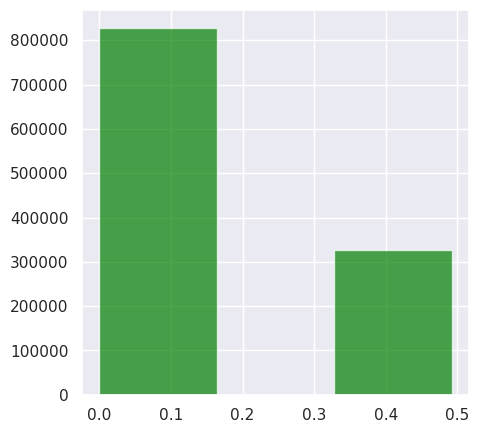

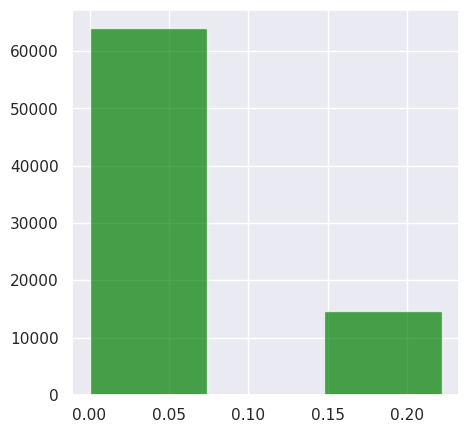

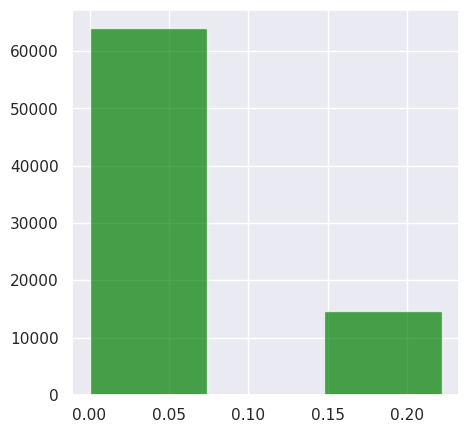

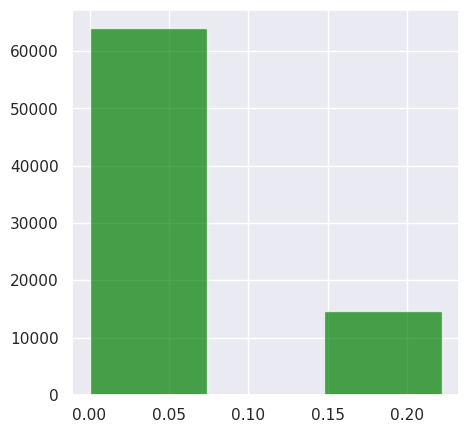

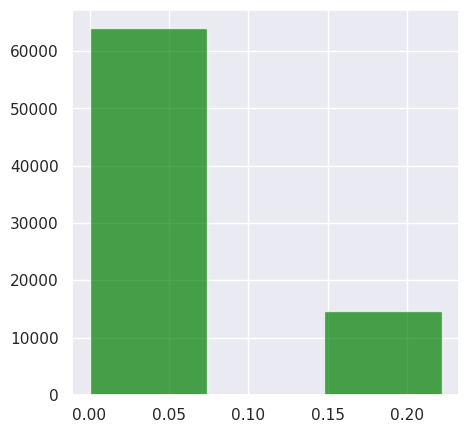

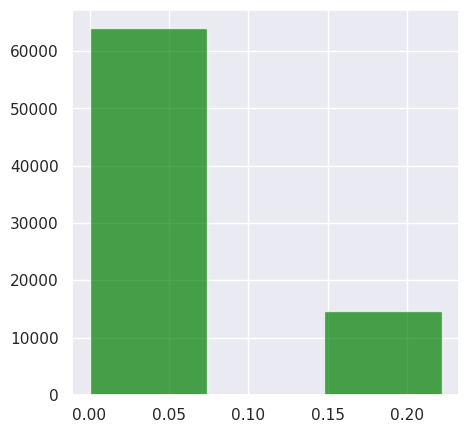

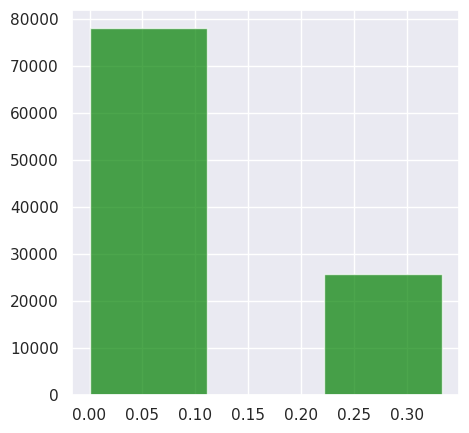

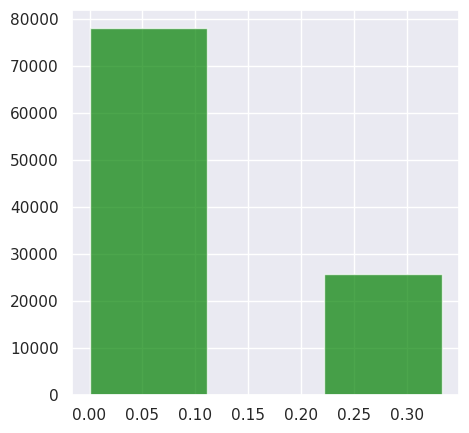

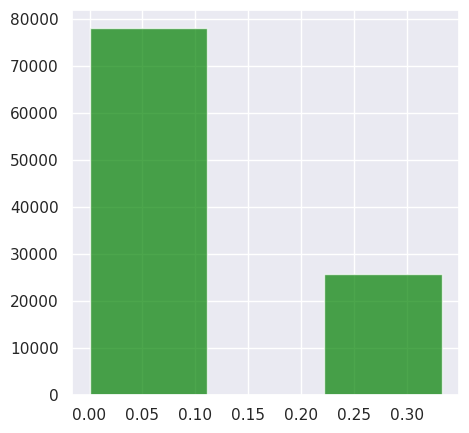

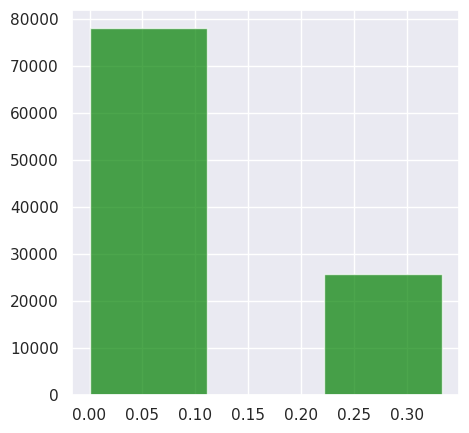

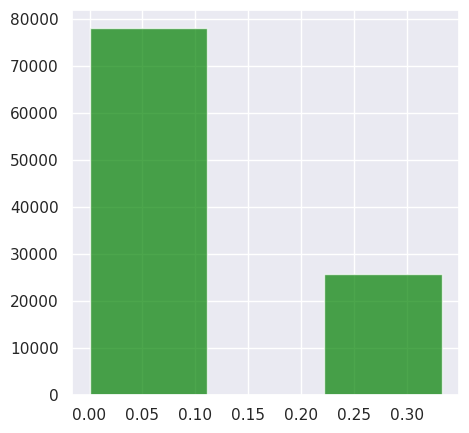

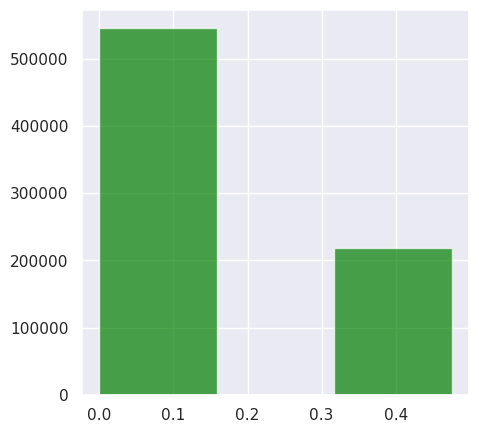

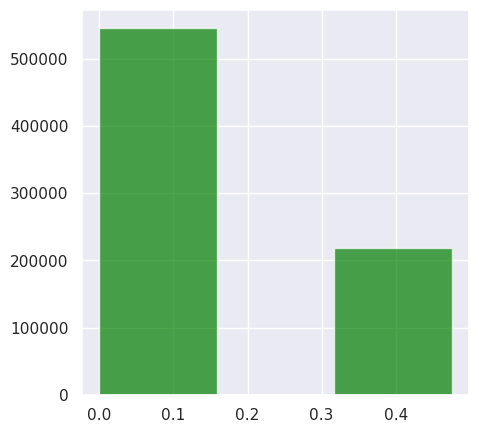

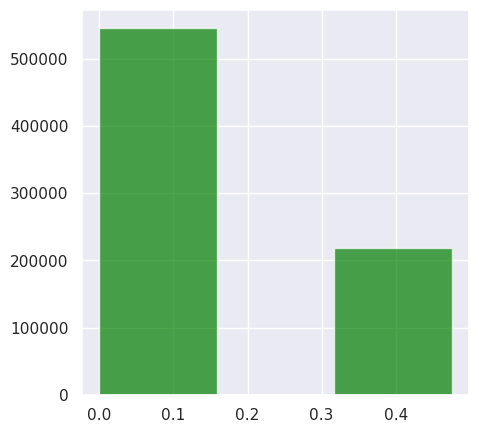

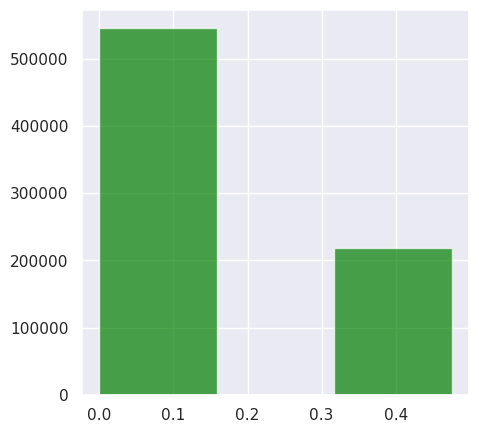

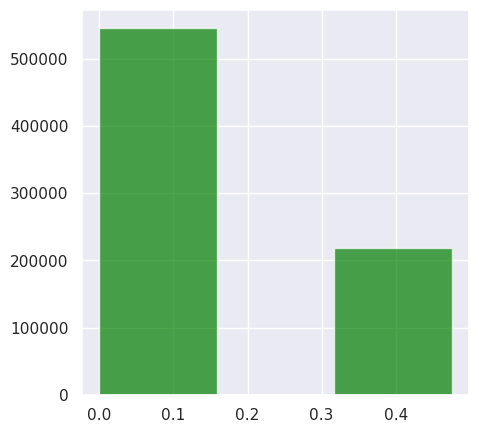

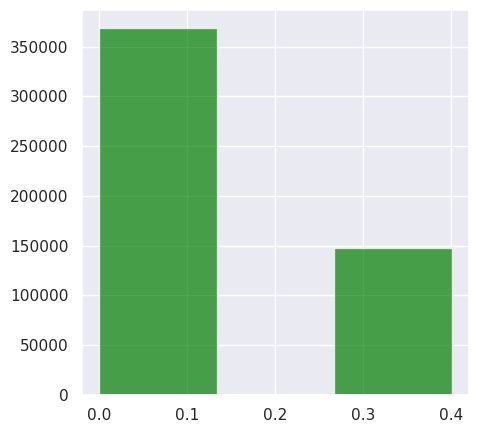

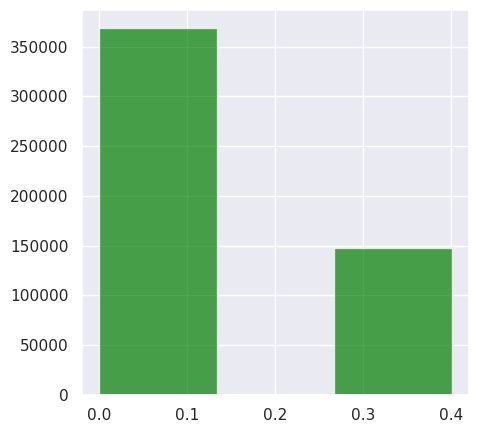

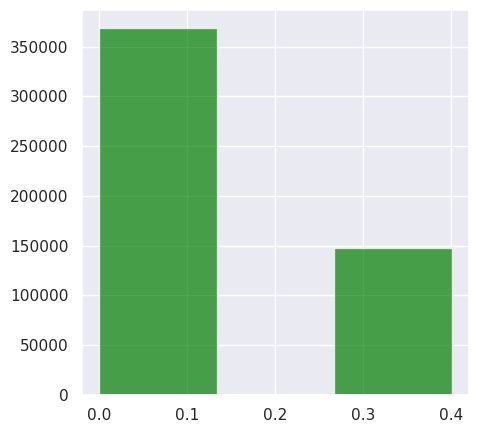

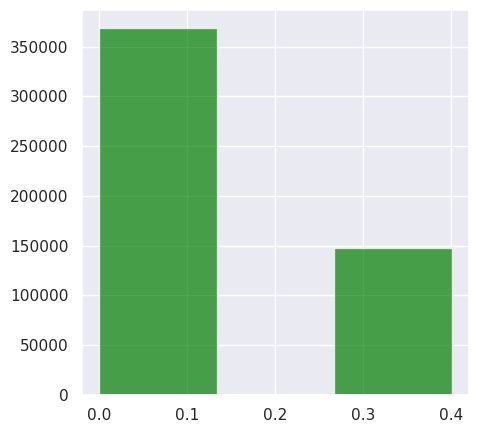

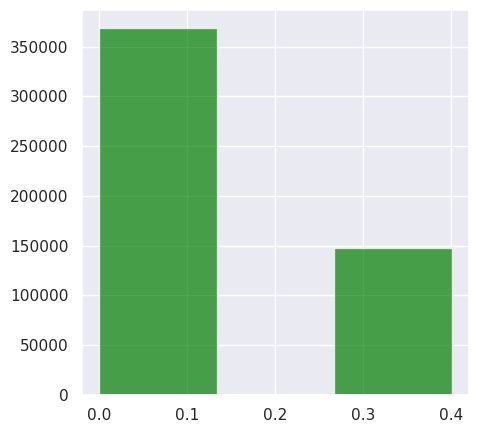

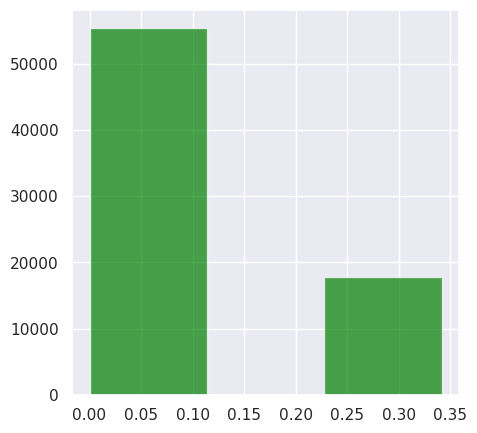

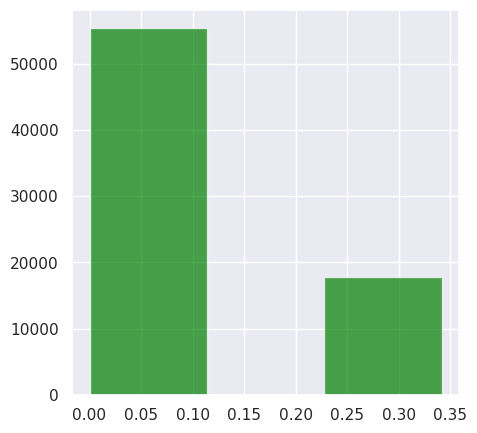

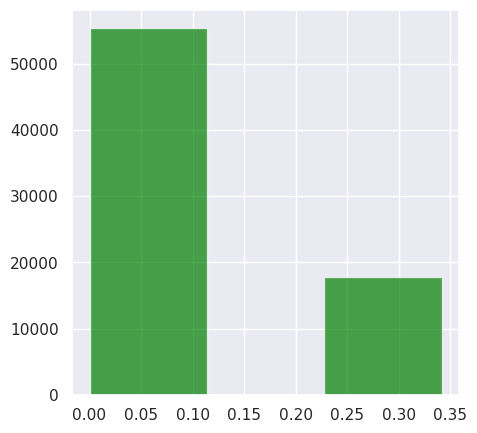

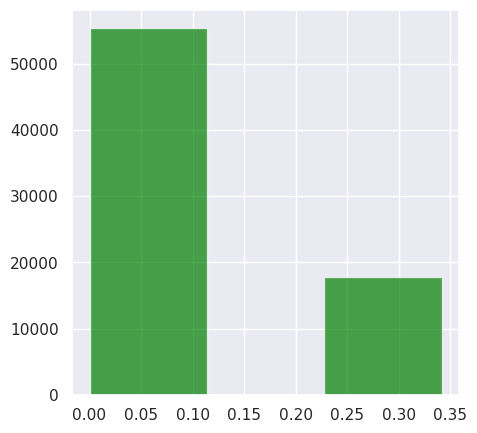

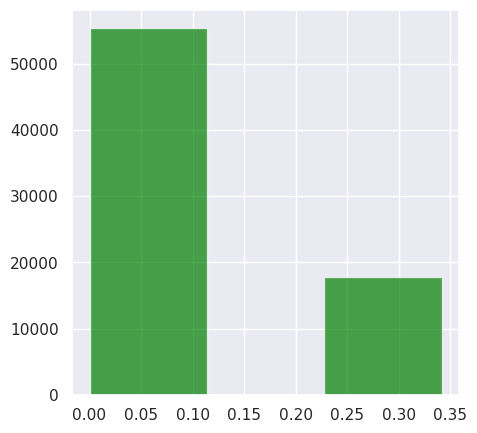

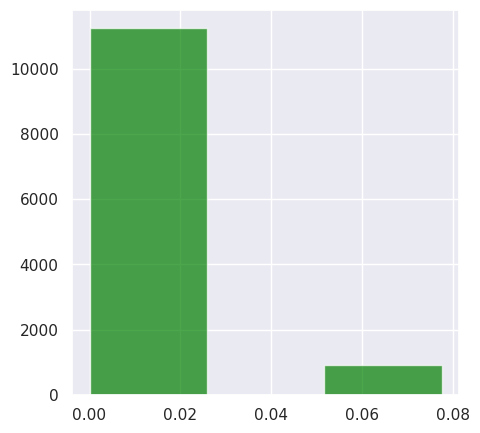

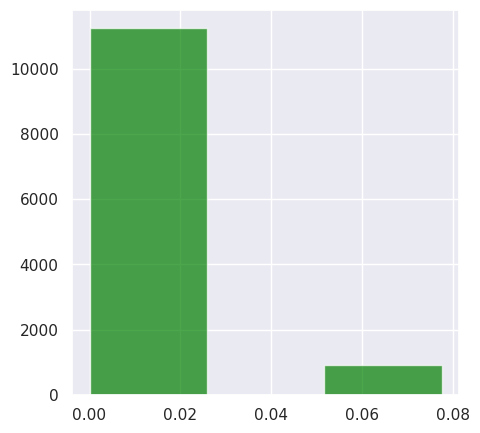

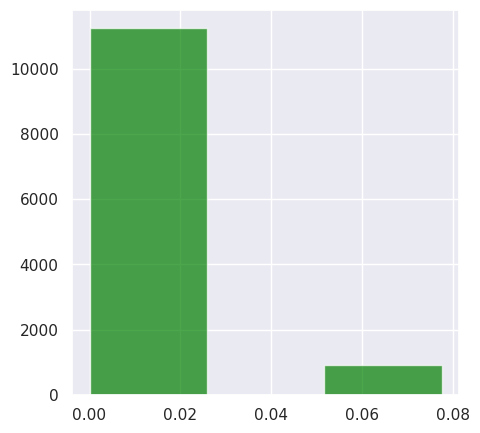

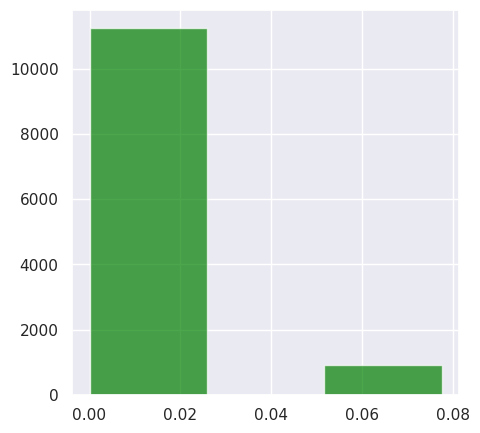

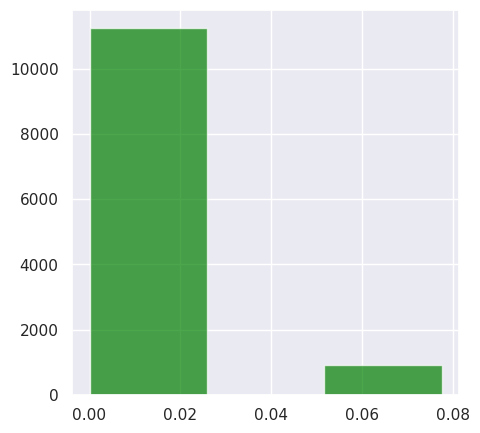

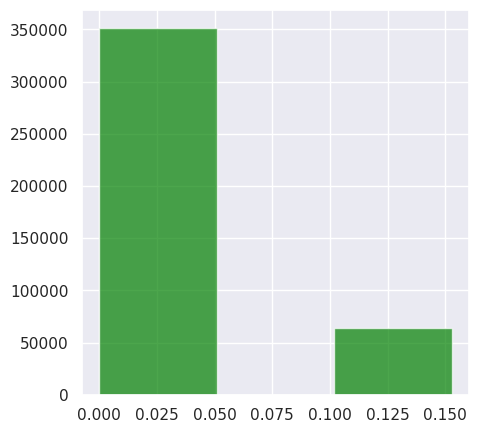

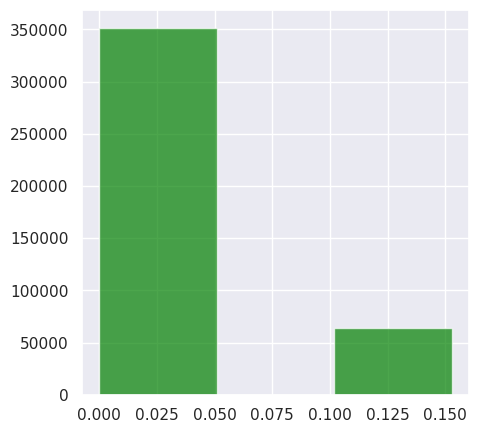

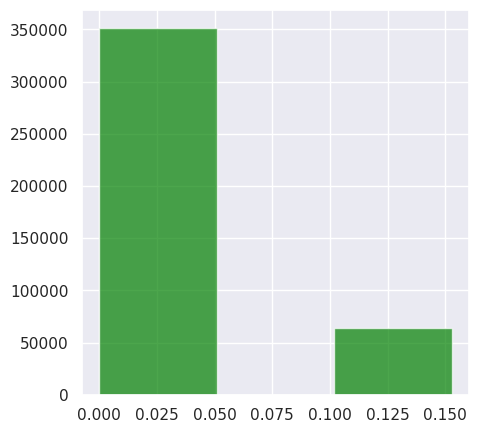

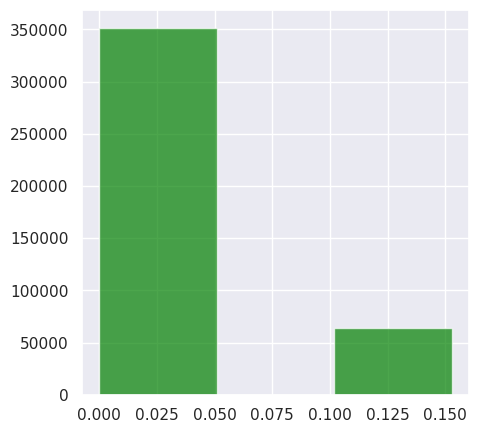

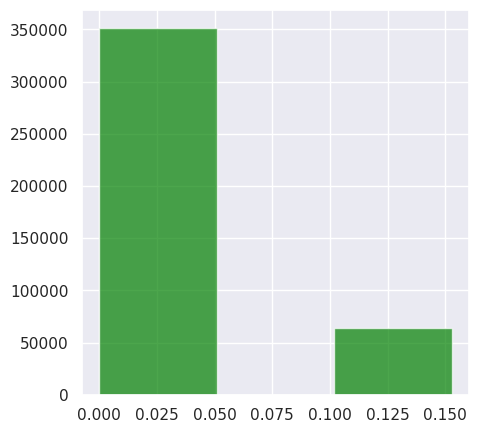

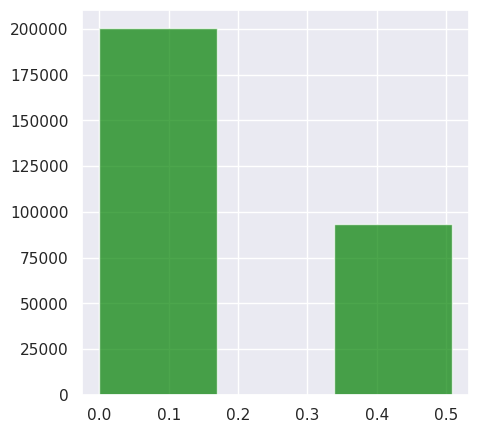

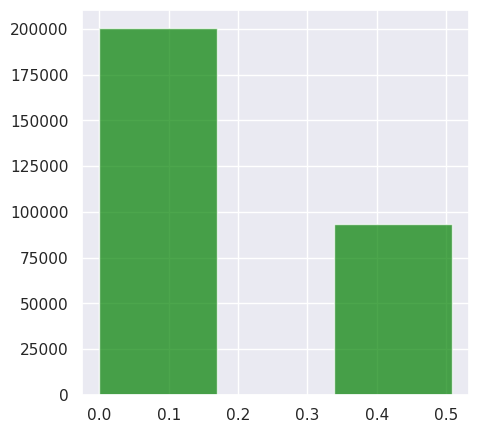

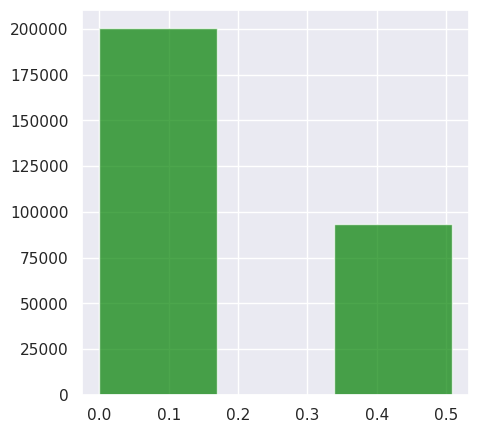

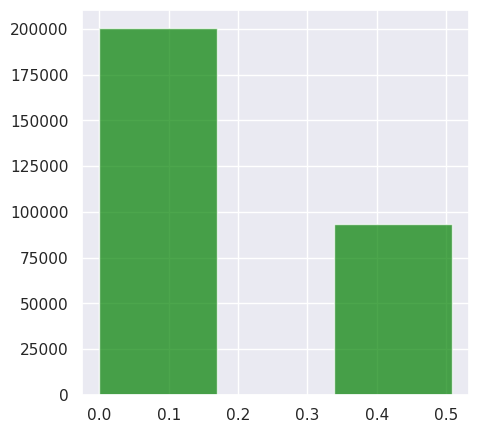

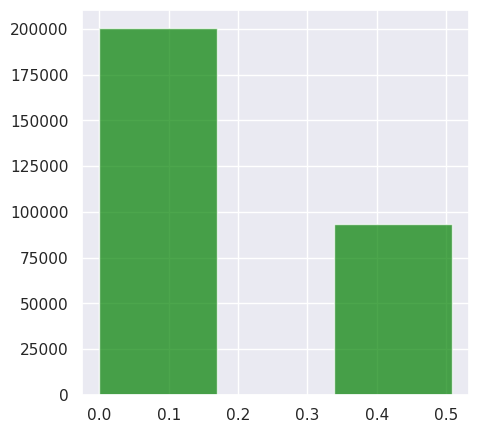

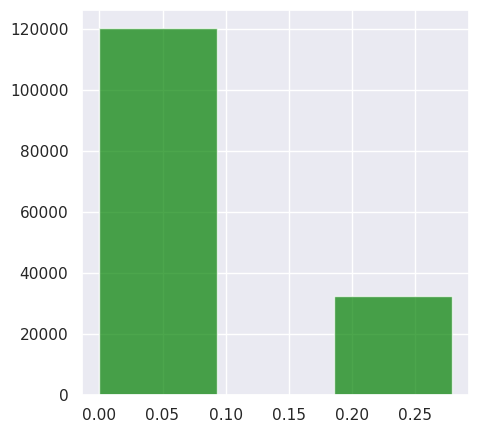

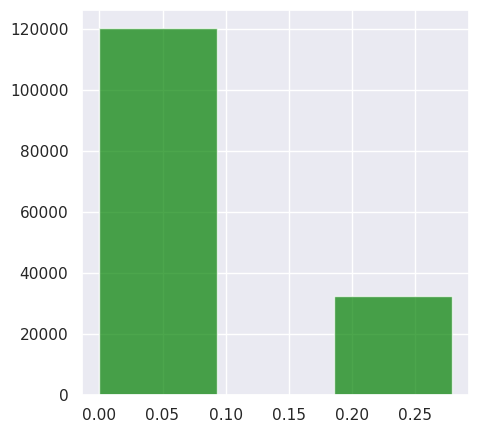

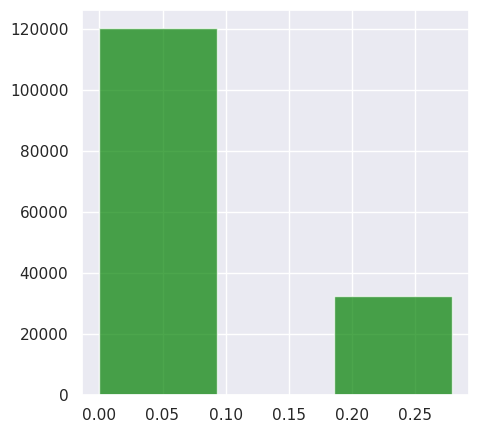

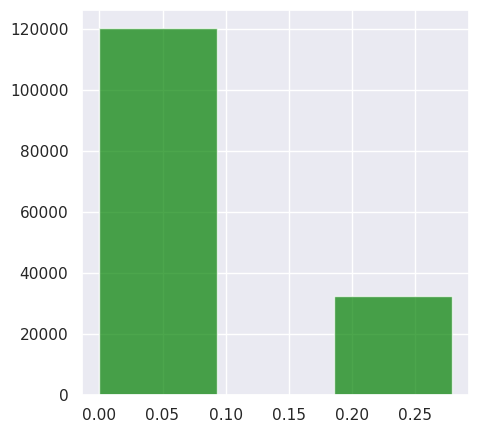

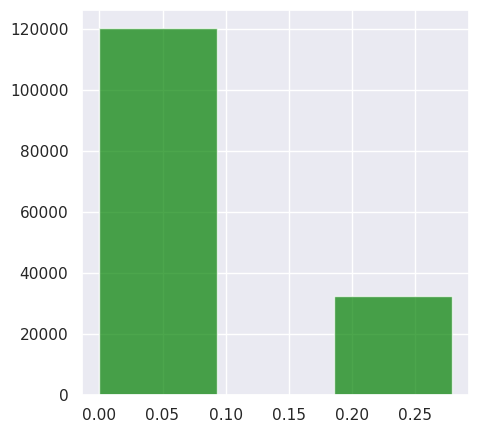

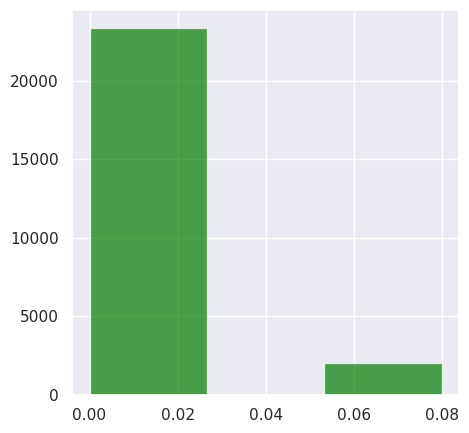

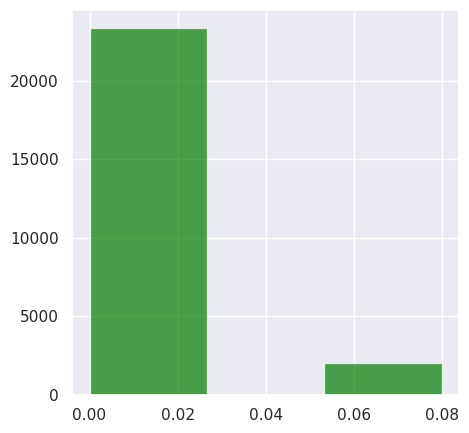

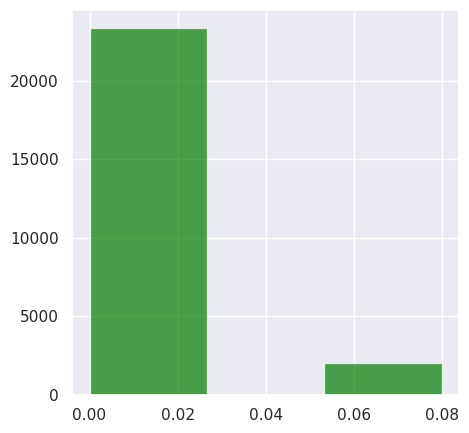

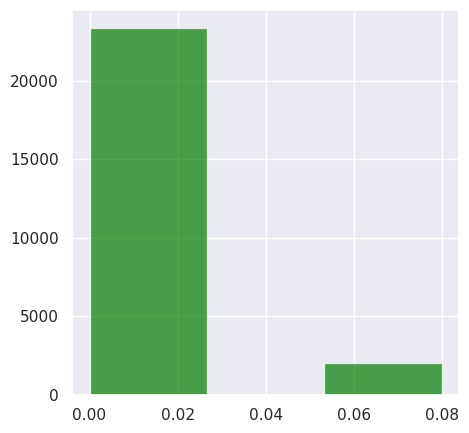

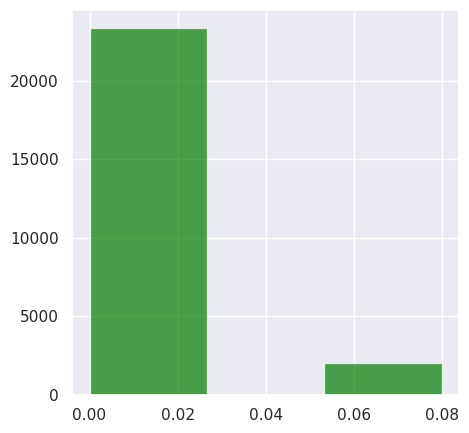

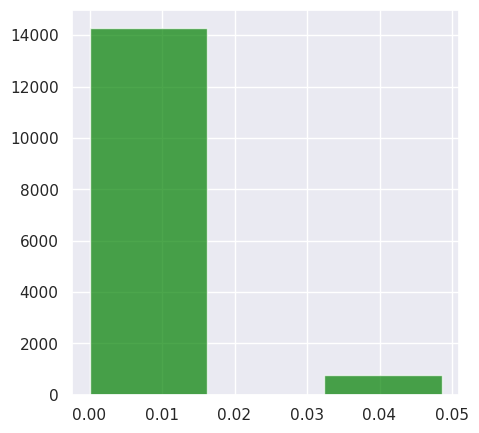

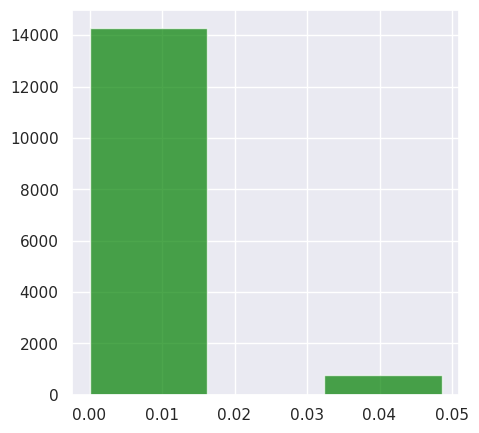

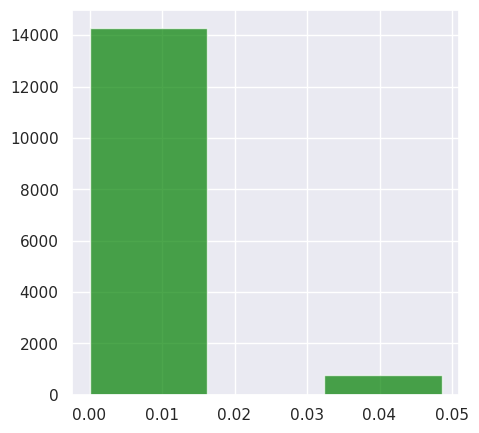

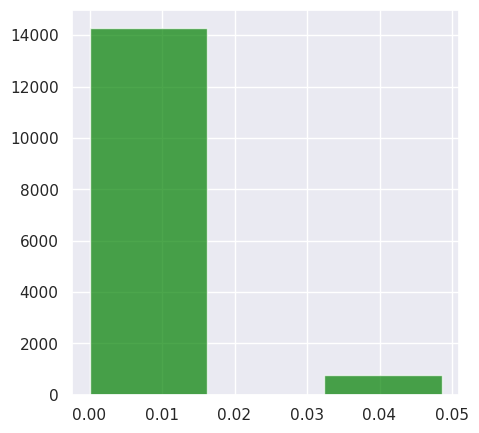

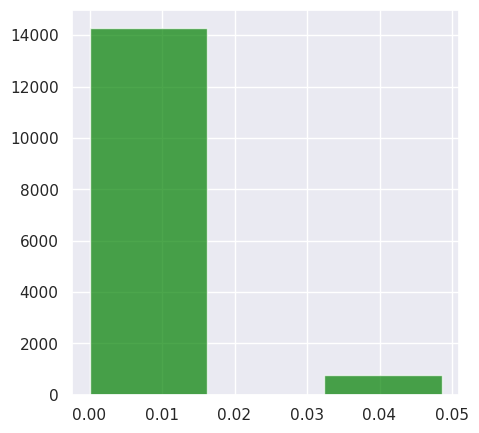

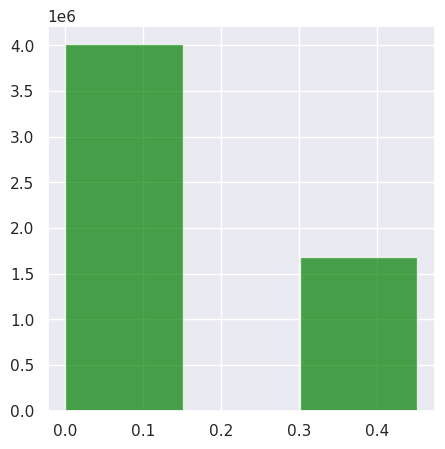

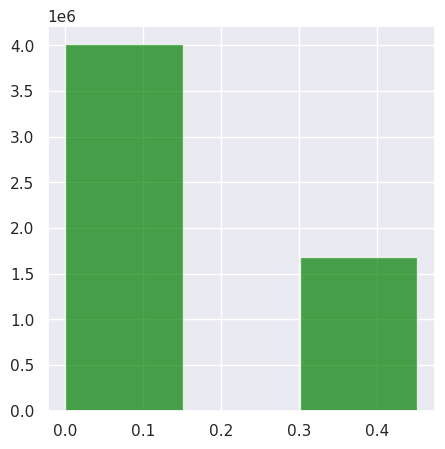

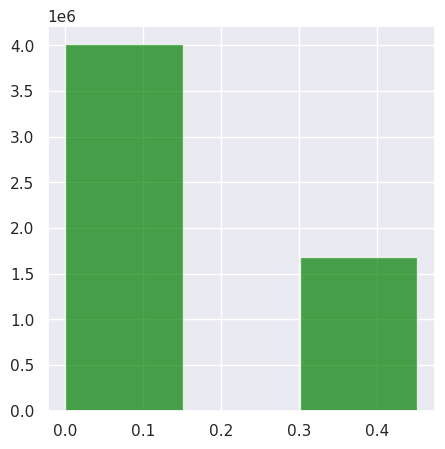

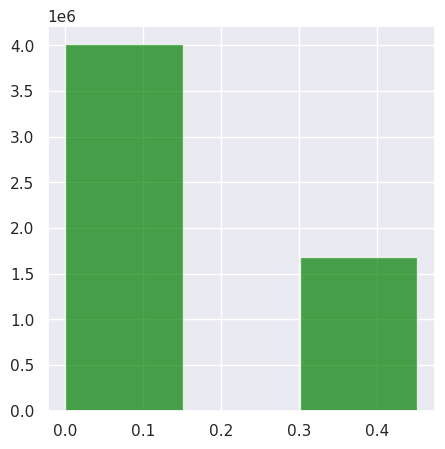

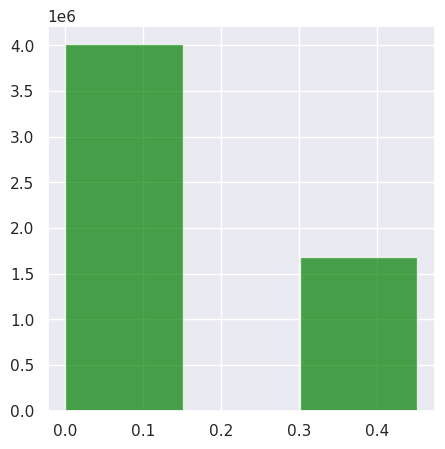

In [8]:
import json
import numpy as np
from scipy.stats import skew, kurtosis
import csv
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

df_exploded = papers.explode('s2fieldsofstudy')
exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
df_sep = pl.from_dicts(exploded_list)
df_res = df_exploded.with_columns(df_sep)
df_filter = df_res.filter(pl.col("source") == "external")
grouped = df_filter.groupby('category')
newDF = []
fos = []
grp = []

records = []
results = []

csv_list = []


for cat, group in grouped:
    print(cat)
    for i in [(1996,2000),(2001,2005),(2006,2010),(2011,2015),(2016,2020)]:

        group_filter = group.filter(pl.col("year").is_in(list(range(i[0],i[1]))))
        print("----------------------")
       
        print(len(group_filter))
        
        ccList = group["influentialcitationcount"].to_list()
        carr = np.array(ccList)

        
        
        # Sample data for Citation Count and Total Records columns
        citation_count = np.array(ccList)
        constant = 1

        # Perform Box-Cox transformation for both columns
        transformed_inf_count, lambda_citation = stats.boxcox(citation_count + 1)
        
        sk = skew(group["influentialcitationcount"])
        kr = kurtosis(group["influentialcitationcount"])
        
        filtered_ccList = [x + 1 for x in ccList]
        log_list = list(np.log(filtered_ccList))
        log_sk=skew(log_list)
        log_kr=kurtosis(log_list)
        
        bc_sk = skew(transformed_inf_count)
        bc_kr = kurtosis(transformed_inf_count)

        
        obj = {"field":cat, "skew": sk, "kurtosis" : kr, "skew_log": log_sk, "kurtosis_log": log_kr, "skew_bc": bc_sk, "kurtosis_bc":bc_kr}
        csv_list.append(obj)

        group_filter = group.with_columns(influentialCount = pl.lit(transformed_inf_count))
        
        group_pd = group_filter.to_pandas()

        # res = getCitationCountBF(cat,group)
        # records.append(res[0])
        # results.append(res[1])
        fig, axes = plt.subplots(figsize=(5, 5))
        
        (n, bins, patches) = axes.hist(transformed_inf_count, bins=3, color='green', alpha=0.7)
        # print(cat)
        # print(list(bins))
        group_pd['bins'] = None 
        
        for i,bin in enumerate(bins):
            if i+1 < len(bins):
                
                print(bins[i],bins[i+1])
                
                mask = (group_pd['influentialCount'] < bins[i + 1]) & (group_pd['influentialCount'] >= bins[i])
                group_pd.loc[mask, 'bins'] = i + 1
                
        # print(group_pd.head())
        unique_values = group_pd["bins"].unique()
        filtered_records = group_pd[group_pd['bins'] == 1]

        print(unique_values)

In [1]:
papers = pl.read_parquet("/dataHDD1/pmData/s2orcParsed/combinedPapers.parquet")
papers.columns

NameError: name 'pl' is not defined